**PRACTICAL NO_01:  INTELLIGENT AGENT - VACUUM CLEANER**

Name: Sakshi Kailas Shewale

PRN: 202401040126

Roll No.: 31

Batch: A2

Class: T.Y. B.Tech Computer Engineering

Subject: Artificial Intelligence and Machine Learning

GitHub:
https://github.com/sakshishewale01/AI_Practical_Assignment_1.1.git

# Title

## Implementation of a Smart Robotic Vacuum Cleaner Agent using Python

---

# Aim

To design and implement an intelligent vacuum cleaner agent using Python that can perceive the condition of rooms, clean dirty rooms, move between connected locations, manage its battery, and return to the charging station when the battery level becomes low.

---

# Experiment Objectives

1. To understand the concept of an intelligent agent.
2. To design a simple vacuum cleaner agent using Python.
3. To implement perception, decision-making, and actions in the agent.
4. To allow the agent to identify dirty and clean rooms.
5. To implement movement between different locations.
6. To implement battery management and a charging mechanism.
7. To understand the PEAS framework for an intelligent vacuum cleaner agent.

---

# Experiment Outcome: PEAS

## P – Performance Measure

The performance of the vacuum agent is measured using:

- Number of rooms cleaned
- Cleaning score
- Number of movements
- Battery usage
- Number of charging sessions
- Number of steps taken
- Efficiency of the agent

## E – Environment

The environment consists of four locations:

The locations are connected to allow the agent to move between different rooms.

The initial environment is:

- **A** – Clean and used as the charging station
- **B** – Randomly clean or dirty
- **C** – Initially dirty
- **D** – Initially dirty

## A – Actuators

The vacuum agent can perform the following actions:

- **SUCK** – Cleans the current dirty room.
- **MOVE** – Moves to another connected location.
- **RETURN** – Returns to the charging station.
- **CHARGE** – Recharges the battery.
- **REST** – Stops after completing the cleaning task.

## S – Sensors

The agent uses its perception function to detect:

- Whether the current room is dirty or clean
- Current location of the agent
- Battery level
- Available neighboring locations

---

# Theory / Conceptual Details

A vacuum cleaner is a simple example of an intelligent agent. It observes the condition of the current room and decides what action should be performed.

If the current room is dirty, the agent performs the **SUCK** action. If the room is already clean, the agent moves to another available room.

In this program, the vacuum agent has the following capabilities:

1. **Perception** – Detects whether the current location is dirty or clean.
2. **Cleaning** – Cleans a dirty location.
3. **Movement** – Moves between connected locations.
4. **Battery Management** – Checks the battery level before continuing.
5. **Charging** – Returns to location A when the battery becomes low.
6. **Memory** – Stores visited and cleaned locations.
7. **Dynamic Environment** – Dirt can appear again with a small probability.
8. **Performance Measurement** – Maintains a score based on cleaning and movement.

### Battery Management

The agent starts with a battery level of **100%**.

The low battery threshold is **20%**. When the battery becomes equal to or less than 20%, the agent returns to the charging station and recharges its battery.

- Cleaning a room consumes **10% battery**.
- Moving to another location consumes **5% battery**.
- Cleaning gives a positive score.
- Movement has a small penalty.

---

# Flowchart


Saving Screenshot 2026-08-09 001332.png to Screenshot 2026-08-09 001332.png


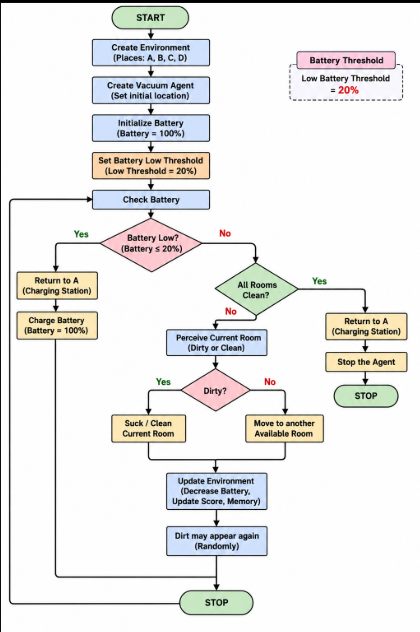

In [ ]:
from google.colab import files
from IPython.display import display, Image

uploaded = files.upload()

filename = next(iter(uploaded))
display(Image(filename=filename, width=650))

# Result Analysis

The Smart Robotic Vacuum Cleaner Agent successfully interacts with the given environment and performs cleaning actions according to the condition of each room.

The agent performs the following activities:

- Detects whether the current room is clean or dirty.
- Cleans the room when it is dirty.
- Moves to another available room when the current room is clean.
- Monitors the battery level during execution.
- Returns to the charging station when the battery level reaches the low battery threshold of **20%**.
- Recharges the battery and continues the cleaning process.
- Keeps track of visited and cleaned locations.
- Maintains the number of movements and charging sessions.
- Updates the performance score after different actions.

Since **C and D are initially dirty**, the agent has cleaning tasks available in these rooms. The exact sequence of movement may vary because the starting location and some movements are selected randomly.

The agent continues the cleaning process until all the required rooms are clean, the battery requires charging, or the maximum step limit is reached.

---

# Conclusion

The **Smart Robotic Vacuum Cleaner Agent** was successfully implemented using Python.

The experiment demonstrates how an intelligent agent can **perceive its environment, make decisions, and perform appropriate actions** according to the current situation.

The **PEAS framework** was used to define the performance measure, environment, actuators, and sensors of the vacuum cleaner agent.

The program also demonstrates important intelligent-agent features such as:

- Battery management
- Charging mechanism
- Movement between locations
- Perception of the environment
- Agent memory
- Dynamic dirt generation
- Performance measurement

Therefore, this experiment provides a practical understanding of how an intelligent agent can be designed to perform a task **autonomously in a given environment**.

# PYTHON CODE

In [ ]:
import random


class Environment:
    def __init__(self):
        # 0 means clean and 1 means dirty
        self.locationCondition = {
            'A': 0,
            'B': random.randint(0, 1),
            'C': 1,
            'D': 1
        }

        # A is the charging station
        self.chargingStation = 'A'

        # Connections between the locations
        self.neighbours = {
            'A': ['B', 'C'],
            'B': ['A', 'D'],
            'C': ['A', 'D'],
            'D': ['B', 'C']
        }

        # No obstacles initially
        self.obstacles = set()


class SmartVacuumAgent:
    def __init__(self, environment):
        self.environment = environment

        # Agent starts from one of the rooms
        self.location = random.choice(['B', 'C', 'D'])

        # Battery settings
        self.battery = 100
        self.maxBattery = 100
        self.lowBattery = 20

        # Performance information
        self.score = 0
        self.steps = 0
        self.moves = 0
        self.cleanedLocations = 0
        self.chargingCount = 0

        # Stores visited and cleaned locations
        self.visited = set()
        self.cleaned = set()

        # Agent status
        self.status = "CLEANING"

        # Maximum number of steps
        self.maxSteps = 50

        # Probability of new dirt appearing
        self.dynamicDirtProbability = 0.10

    def perceive(self):
        if self.environment.locationCondition[self.location] == 1:
            return "DIRTY"

        return "CLEAN"

    def checkBattery(self):
        print("Battery:", self.battery, "%")

        if self.battery <= self.lowBattery:
            print("Battery is low!")
            return False

        return True

    def cleanLocation(self):
        print("Action: SUCK")

        # Clean the current location
        self.environment.locationCondition[self.location] = 0

        self.cleaned.add(self.location)
        self.cleanedLocations += 1

        # Cleaning consumes 10% battery
        self.battery -= 10

        # Give reward for cleaning
        self.score += 10

        print("Location", self.location, "cleaned.")
        print("Battery:", self.battery, "%")

    def chooseNextLocation(self):
        possibleLocations = self.environment.neighbours[self.location]

        # Remove blocked locations
        possibleLocations = [
            location for location in possibleLocations
            if location not in self.environment.obstacles
        ]

        # Prefer locations that have not been visited
        unvisited = [
            location for location in possibleLocations
            if location not in self.visited
        ]

        if unvisited:
            return random.choice(unvisited)

        return random.choice(possibleLocations)

    def move(self):
        nextLocation = self.chooseNextLocation()

        print("Action: MOVE")
        print("Moving from", self.location, "to", nextLocation)

        self.location = nextLocation
        self.moves += 1

        # Movement consumes 5% battery
        self.battery -= 5

        # Small penalty for movement
        self.score -= 1

        print("Battery:", self.battery, "%")

    def returnToChargingStation(self):
        self.status = "RETURNING_TO_CHARGER"

        print("\nLow battery!")
        print("Returning to charging station...")

        while self.location != self.environment.chargingStation:

            possibleLocations = self.environment.neighbours[self.location]

            possibleLocations = [
                location for location in possibleLocations
                if location not in self.environment.obstacles
            ]

            # If charging station is directly connected, go there
            if self.environment.chargingStation in possibleLocations:
                nextLocation = self.environment.chargingStation
            else:
                nextLocation = random.choice(possibleLocations)

            print("Moving from", self.location, "to", nextLocation)

            self.location = nextLocation
            self.moves += 1
            self.steps += 1

            # Movement consumes 5% battery
            self.battery -= 5

            self.score -= 1

            print("Battery:", self.battery, "%")

            if self.battery <= 0:
                print("Battery is empty. Robot stopped.")
                break

        if self.location == self.environment.chargingStation:
            print("Reached charging station.")

    def chargeBattery(self):
        self.status = "CHARGING"

        print("\nCharging battery...")
        print("Current battery:", self.battery, "%")

        self.chargingCount += 1

        # Recharge to maximum battery
        self.battery = self.maxBattery

        # Small penalty for charging
        self.score -= 2

        print("Battery charged to:", self.battery, "%")

        self.status = "CLEANING"

    def allLocationsClean(self):
        for location in self.environment.locationCondition:

            # Charging station does not need cleaning
            if location == self.environment.chargingStation:
                continue

            if self.environment.locationCondition[location] == 1:
                return False

        return True

    def generateDynamicDirt(self):
        for location in self.environment.locationCondition:

            # Charging station is always clean
            if location == self.environment.chargingStation:
                continue

            # Dirt can appear randomly
            if random.random() < self.dynamicDirtProbability:

                if self.environment.locationCondition[location] == 0:
                    self.environment.locationCondition[location] = 1

                    print("New dirt appeared at", location)

    def rest(self):
        self.status = "RESTING"

        print("\nRobot is resting at the charging station.")
        print("All cleaning tasks are completed.")
        print("Battery:", self.battery, "%")
        print("Status:", self.status)

    def finalReport(self):
        print("\nFinal Performance Report")
        print("-" * 35)

        print("\nFinal Environment:")

        for location, condition in self.environment.locationCondition.items():

            if condition == 0:
                print(location, ": CLEAN")
            else:
                print(location, ": DIRTY")

        print("\nAgent Information:")

        print("Final Location:", self.location)
        print("Final Battery:", self.battery, "%")
        print("Total Steps:", self.steps)
        print("Total Movements:", self.moves)
        print("Locations Cleaned:", self.cleanedLocations)
        print("Charging Sessions:", self.chargingCount)
        print("Visited Locations:", self.visited)
        print("Cleaned Locations:", self.cleaned)
        print("Final Score:", self.score)

        if self.steps > 0:
            efficiency = self.score / self.steps
            print("Efficiency: %.2f" % efficiency)

        print("Final Status:", self.status)

    def run(self):
        print("\nSMART ROBOTIC VACUUM AGENT")
        print("-" * 35)

        print("\nInitial Environment:")

        for location, condition in self.environment.locationCondition.items():

            if condition == 0:
                print(location, ": CLEAN")
            else:
                print(location, ": DIRTY")

        print("Charging Station:", self.environment.chargingStation)
        print("Starting Location:", self.location)
        print("Initial Battery:", self.battery, "%")
        print("Low Battery Threshold:", self.lowBattery, "%")

        while self.steps < self.maxSteps:

            self.steps += 1

            print("\nStep:", self.steps)
            print("Location:", self.location)
            print("Status:", self.status)

            # Remember the current location
            self.visited.add(self.location)

            # Check battery level
            if not self.checkBattery():

                self.returnToChargingStation()

                if self.location == self.environment.chargingStation:
                    self.chargeBattery()

                continue

            # Check whether all rooms are clean
            if self.allLocationsClean():

                print("\nAll locations are clean!")

                # Return to charging station
                if self.location != self.environment.chargingStation:
                    self.returnToChargingStation()

                if self.location == self.environment.chargingStation:
                    self.rest()

                break

            # Perceive the current room
            percept = self.perceive()

            print("Percept:", percept)

            if percept == "DIRTY":

                # Clean the room
                self.cleanLocation()

            else:

                # Move if the room is already clean
                print("Location is already clean.")
                self.move()

            # Dirt can appear again
            self.generateDynamicDirt()

        # Maximum step condition
        if self.steps >= self.maxSteps:

            print("\nMaximum step limit reached.")

            if self.location != self.environment.chargingStation:
                self.returnToChargingStation()

            if self.location == self.environment.chargingStation:
                self.rest()

        # Display final results
        self.finalReport()


# Create the environment
theEnvironment = Environment()

# Create the vacuum agent
theVacuum = SmartVacuumAgent(theEnvironment)

# Start the vacuum agent
theVacuum.run()


SMART ROBOTIC VACUUM AGENT
-----------------------------------

Initial Environment:
A : CLEAN
B : DIRTY
C : DIRTY
D : DIRTY
Charging Station: A
Starting Location: B
Initial Battery: 100 %
Low Battery Threshold: 20 %

Step: 1
Location: B
Status: CLEANING
Battery: 100 %
Percept: DIRTY
Action: SUCK
Location B cleaned.
Battery: 90 %

Step: 2
Location: B
Status: CLEANING
Battery: 90 %
Percept: CLEAN
Location is already clean.
Action: MOVE
Moving from B to D
Battery: 85 %

Step: 3
Location: D
Status: CLEANING
Battery: 85 %
Percept: DIRTY
Action: SUCK
Location D cleaned.
Battery: 75 %
New dirt appeared at D

Step: 4
Location: D
Status: CLEANING
Battery: 75 %
Percept: DIRTY
Action: SUCK
Location D cleaned.
Battery: 65 %
New dirt appeared at D

Step: 5
Location: D
Status: CLEANING
Battery: 65 %
Percept: DIRTY
Action: SUCK
Location D cleaned.
Battery: 55 %

Step: 6
Location: D
Status: CLEANING
Battery: 55 %
Percept: CLEAN
Location is already clean.
Action: MOVE
Moving from D to C
Battery: 50 %